# DEV · Compra Fácil Bajío: reseñas negativas
**Equipo:** León Franco Fernando, Mendoza Rodriguez Rodrigo, Muñoz Delgado Gael Arturo
**Datos:** [SetFit/amazon_reviews_multi_es](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es), Amazon Multilingual Reviews en español (Keung et al., 2020)
**Entorno:** Google Colab con GPU T4

**Lo que pide el cliente, en la prueba y con umbral de 0.5:**

| Especificación | Mínimo |
|---|---|
| Exhaustividad: de cada 100 reseñas negativas, cuántas marca | 90 % |
| Precisión: de cada 100 reseñas marcadas, cuántas son negativas | 85 % |
| Modelo propio, entrenado por el equipo | Sin LLM por API |

**Regla de trabajo:** todas las decisiones salen de la validación. La prueba se abre una sola vez, en el paso 8, cuando el modelo ya está elegido. Si ahí no se cumple alguna especificación, no se reajusta: se reporta con honestidad.

**Cómo correrlo:** Entorno de ejecución → Cambiar tipo de entorno → T4, y después Ejecutar todo. Calcula entre 30 y 60 minutos, y deja la pestaña abierta.

## 1. Entorno
`TF_FORCE_GPU_ALLOW_GROWTH` evita que TensorFlow acapare la GPU, porque BETO la necesita después con PyTorch.

In [1]:
import gc
import os
import shutil
import sys
import textwrap
import time

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["USE_TF"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import torch
import transformers
from IPython.display import Markdown, display
from keras import layers
from sklearn.metrics import confusion_matrix
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments)

SEED = 2711
UMBRAL = 0.5
MIN_EXHAUSTIVIDAD = 0.90
MIN_PRECISION = 0.85
MARGEN_MINIMO = 0.01

keras.utils.set_random_seed(SEED)
transformers.set_seed(SEED)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_colwidth", 140)

gpu_tf = len(tf.config.list_physical_devices("GPU")) > 0
gpu_torch = torch.cuda.is_available()
print(f"Python {sys.version.split()[0]} · Keras {keras.__version__} · motor {keras.backend.backend()} · TensorFlow {tf.__version__}")
print(f"PyTorch {torch.__version__} · transformers {transformers.__version__}")
print(f"GPU en TensorFlow: {gpu_tf} · GPU en PyTorch: {gpu_torch}")
if not (gpu_tf and gpu_torch):
    print("AVISO: sin GPU, BETO y la Bi-LSTM tardarían demasiado. En Colab elige T4.")

Python 3.13.16 · Keras 3.13.2 · motor tensorflow · TensorFlow 2.21.0
PyTorch 2.11.0+cu130 · transformers 5.22.0
GPU en TensorFlow: True · GPU en PyTorch: True


## 2. Carga y prueba del cliente
Es la carga y la prueba que indica el examen, sin cambios. Después de esta celda, `test`, `prueba`, `X_prueba` y `y_prueba` no se usan hasta el paso 8.

**Ojo con la etiqueta:** aquí **1 = NEGATIVA**, así que la clase que importa es la 1 y la exhaustividad y la precisión se miden sobre ella.

In [2]:
import pandas as pd

URL = "https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/main/{}.jsonl"
partes = {p: pd.read_json(URL.format(p), lines=True) for p in ["train", "validation", "test"]}
for df in partes.values():
    df["estrellas"] = df["label"] + 1  # label va de 0 a 4
train, val, test = partes["train"], partes["validation"], partes["test"]

# Prueba del cliente: la partición test sin las de 3 estrellas (4,000 reseñas, mitad negativas).
# 1 = negativa. No la toquen hasta el final.
prueba = test[test["estrellas"] != 3]
X_prueba, y_prueba = prueba["text"].values, (prueba["estrellas"] <= 2).astype(int).values

print(f"Entrenamiento: {len(train):,} · validación: {len(val):,} · partición test: {len(test):,}")
print(f"Prueba del cliente: {len(y_prueba):,} reseñas, {y_prueba.mean():.1%} negativas")

Entrenamiento: 200,000 · validación: 5,000 · partición test: 5,000
Prueba del cliente: 4,000 reseñas, 50.0% negativas


## 3. Exploración
Todo se explora con la partición de entrenamiento, para no mirar la prueba.

Columnas: ['id', 'text', 'label', 'label_text', 'estrellas']
Textos faltantes: 0 · vacíos: 0 · repetidos: 1,736


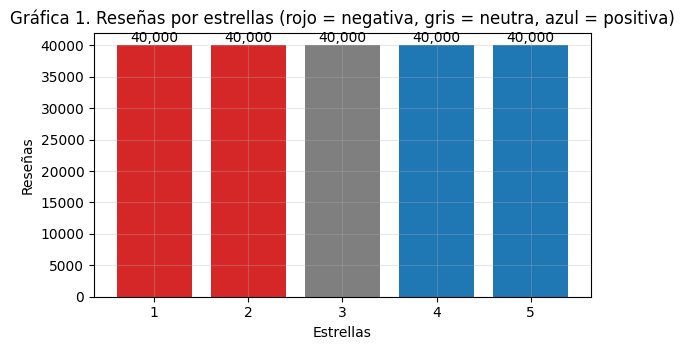

In [3]:
conteo = train["estrellas"].value_counts().sort_index()
faltantes = int(train["text"].isna().sum())
vacias = int((train["text"].astype(str).str.strip() == "").sum())
repetidas = int(train["text"].duplicated().sum())
print(f"Columnas: {list(train.columns)}")
print(f"Textos faltantes: {faltantes} · vacíos: {vacias} · repetidos: {repetidas:,}")

colores = {1: "tab:red", 2: "tab:red", 3: "tab:gray", 4: "tab:blue", 5: "tab:blue"}
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(conteo.index.astype(str), conteo.values, color=[colores[e] for e in conteo.index])
for i, valor in enumerate(conteo.values):
    ax.text(i, valor, f"{valor:,}", ha="center", va="bottom")
ax.set_title("Gráfica 1. Reseñas por estrellas (rojo = negativa, gris = neutra, azul = positiva)")
ax.set_xlabel("Estrellas")
ax.set_ylabel("Reseñas")
plt.tight_layout()
plt.show()

In [4]:
for estrellas in [1, 2, 3, 4, 5]:
    ejemplo = train[train["estrellas"] == estrellas].sample(1, random_state=SEED)["text"].iloc[0]
    print(f"{estrellas}★ {textwrap.shorten(ejemplo, width=170, placeholder='…')}\n")

1★ No sirve de nada, sigo gordo y me la puse por como media hora, esperaba quedar plan modelo de Armani pero no 😭

2★ La batería dura todo el día con creces pero tiene una molesta app de publicidad que no he sabido quitar, es realmente un problema. A demás cada poco me daba errores de…

3★ No son los mejores botones del mundo, y se nota en los acabados (algunos vienen con rebabas, etc) pero tampoco son horrorosos. Vienen en una cajita muy útil con…

4★ Las cremayeras son malas por lo demas perfecto

5★ Excelente compra, buen sonido y fácil de instalar. Envío rapidísimo y en perfectas condiciones.



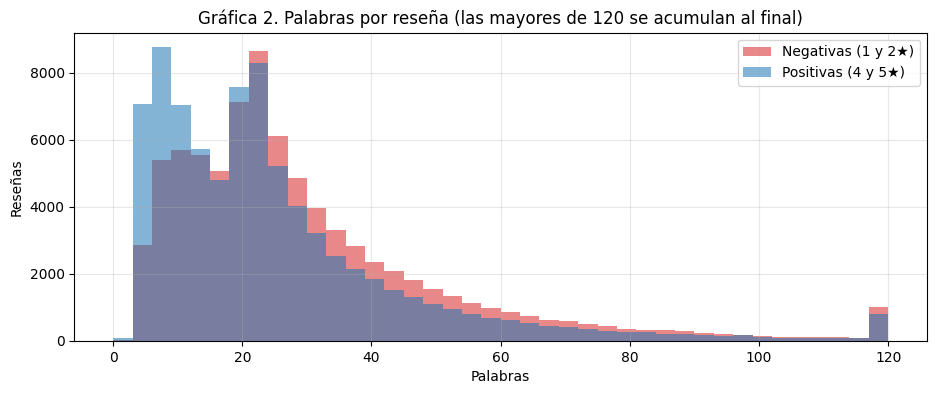

Mediana de palabras: 22 · percentil 95: 71
Cociente de Google (muestras ÷ mediana): 7,273. La regla sugiere probar secuencia si pasa de 1,500.


In [5]:
palabras = train["text"].astype(str).str.split().str.len()
es_negativa = train["estrellas"] <= 2
sin_tres = train["estrellas"] != 3

fig, ax = plt.subplots()
limite = 120
contenedores = np.arange(0, limite + 3, 3)
ax.hist(palabras[es_negativa].clip(upper=limite), bins=contenedores, alpha=0.55, color="tab:red", label="Negativas (1 y 2★)")
ax.hist(palabras[~es_negativa & sin_tres].clip(upper=limite), bins=contenedores, alpha=0.55, color="tab:blue", label="Positivas (4 y 5★)")
ax.set_title(f"Gráfica 2. Palabras por reseña (las mayores de {limite} se acumulan al final)")
ax.set_xlabel("Palabras")
ax.set_ylabel("Reseñas")
ax.legend()
plt.show()

mediana = float(palabras[sin_tres].median())
p95 = float(palabras[sin_tres].quantile(0.95))
cociente = int(sin_tres.sum()) / mediana
print(f"Mediana de palabras: {mediana:.0f} · percentil 95: {p95:.0f}")
print(f"Cociente de Google (muestras ÷ mediana): {cociente:,.0f}. La regla sugiere probar secuencia si pasa de 1,500.")

**Lectura de la gráfica 2:** la mayoría de las reseñas son cortas: la mediana es de 22 palabras y el 95 % tiene 71 o menos. Las clases se enciman casi por completo; la diferencia visible es que las positivas abundan más entre 3 y 12 palabras, y las negativas tienden a ser un poco más largas. El largo no alcanza para separarlas: el modelo tiene que leer el contenido.

## 4. Preparación
- **Reseñas de 3 estrellas:** las quitamos de entrenamiento y de validación, porque no son ni buenas ni malas y la prueba del cliente no las incluye, de modo que contarlas de un lado o del otro solo metería ruido en las etiquetas.
- **Validación:** es la partición `validation`, filtrada igual que la prueba, para que sus números se comparen bien.
- **Sin fuga:** se quitan los textos repetidos de entrenamiento y los que también están en validación. Los vocabularios se ajustan solo con entrenamiento. La coincidencia con la prueba solo se mide al final, en el paso 8.
- **Estandarización:** pasa a minúsculas y quita puntuación, incluidos `¿` y `¡`, que la opción de fábrica no quita. No quita palabras como «no», porque cambian el sentido.
- **Vectorización:** TF-IDF de unigramas y bigramas para la red densa, e índices de palabras para la Bi-LSTM. BETO usa su propio tokenizador.

In [6]:
def preparar(tabla):
    sin_neutras = tabla[tabla["estrellas"] != 3].copy()
    sin_neutras["text"] = sin_neutras["text"].astype(str)
    sin_neutras["negativa"] = (sin_neutras["estrellas"] <= 2).astype(int)
    return sin_neutras[["text", "estrellas", "negativa"]]


des_val = preparar(val)
des_train = preparar(train)
n_inicial = len(des_train)
des_train = des_train.drop_duplicates("text")
n_sin_repetidos = len(des_train)
des_train = des_train[~des_train["text"].isin(des_val["text"])].reset_index(drop=True)

x_train, y_train = des_train["text"].to_numpy(dtype=object), des_train["negativa"].to_numpy()
x_val, y_val = des_val["text"].to_numpy(dtype=object), des_val["negativa"].to_numpy()

print(f"Entrenamiento: {n_inicial:,} sin 3★ → {n_sin_repetidos:,} sin repetidos → {len(x_train):,} sin los que están en validación")
print(f"Entrenamiento: {y_train.mean():.1%} negativas · validación: {len(x_val):,} reseñas, {y_val.mean():.1%} negativas")

Entrenamiento: 160,000 sin 3★ → 158,611 sin repetidos → 158,558 sin los que están en validación
Entrenamiento: 50.2% negativas · validación: 4,000 reseñas, 50.0% negativas


In [7]:
MAX_TFIDF = 30_000
MAX_SECUENCIA = 20_000
LONGITUD = 80
LOTE = 256


@keras.saving.register_keras_serializable(package="resenas", name="estandarizar_es")
def estandarizar_es(texto):
    texto = tf.strings.lower(texto, encoding="utf-8")
    return tf.strings.regex_replace(texto, r"[^a-z0-9áéíóúüñ\s]", " ")


def ds_textos(textos, etiquetas=None, mezclar=False):
    lista = [str(t) for t in textos]
    if etiquetas is None:
        ds = tf.data.Dataset.from_tensor_slices(lista)
    else:
        ds = tf.data.Dataset.from_tensor_slices((lista, np.asarray(etiquetas, dtype="float32")))
    if mezclar:
        ds = ds.shuffle(50_000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(LOTE)


def ds_vectorizado(textos, vectorizador, etiquetas=None, mezclar=False):
    ds = ds_textos(textos, etiquetas, mezclar)
    if etiquetas is None:
        ds = ds.map(lambda t: vectorizador(t), num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.map(lambda t, y: (vectorizador(t), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)


t0 = time.time()
vec_tfidf = layers.TextVectorization(max_tokens=MAX_TFIDF, ngrams=2, output_mode="tf_idf", standardize=estandarizar_es)
vec_seq = layers.TextVectorization(max_tokens=MAX_SECUENCIA, output_mode="int", output_sequence_length=LONGITUD,
                                   standardize=estandarizar_es)
vec_tfidf.adapt(ds_textos(x_train))  # solo entrenamiento
vec_seq.adapt(ds_textos(x_train))    # solo entrenamiento
print(f"Vocabularios listos en {time.time() - t0:.0f} s · TF-IDF: {vec_tfidf.vocabulary_size():,} · secuencia: {vec_seq.vocabulary_size():,}")
print("Ejemplo:", tf.strings.reduce_join(estandarizar_es(tf.constant(["¡No FUNCIONÓ! ¿Qué pasó?"]))).numpy().decode("utf-8"))

Vocabularios listos en 341 s · TF-IDF: 30,000 · secuencia: 20,000
Ejemplo:  no funcionó   qué pasó 


### Funciones de medición
Las mismas funciones miden la validación y la prueba, siempre con umbral de 0.5.

El **margen** es lo que sobra sobre la especificación más ajustada: `min(exhaustividad − 0.90, precisión − 0.85)`. Si es negativo, el modelo no cumple.

In [8]:
def metricas(y_real, prob):
    pred = (prob >= UMBRAL).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    exhaustividad = tp / (tp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    return {"exhaustividad": exhaustividad, "precision": precision, "exactitud": (tp + tn) / len(y_real),
            "margen": min(exhaustividad - MIN_EXHAUSTIVIDAD, precision - MIN_PRECISION),
            "vp": int(tp), "fn": int(fn), "vn": int(tn), "fp": int(fp)}


def intervalo_wilson(aciertos, total, z=1.96):
    p = aciertos / total
    centro = (p + z**2 / (2 * total)) / (1 + z**2 / total)
    radio = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return centro - radio, centro + radio


def parametros_keras(red):
    return int(sum(np.prod(peso.shape) for peso in red.trainable_weights))

## 5. Línea base trivial
Marcar **todas** las reseñas como negativas. Tiene exhaustividad perfecta y precisión de 50 %, porque no distingue nada: atención a clientes tendría que leerlo todo. Sirve para ver que una sola métrica engaña, y por eso el cliente pide las dos.

In [9]:
NOMBRE_BASE = "Línea base (todo negativa)"
candidatos = {NOMBRE_BASE: {"tipo": "linea base", "parametros": 0, "orden": 0, "probabilidad": lambda textos: np.ones(len(textos))}}
print({k: round(float(v), 4) for k, v in metricas(y_val, candidatos[NOMBRE_BASE]["probabilidad"](x_val)).items()})

{'exhaustividad': 1.0, 'precision': 0.5, 'exactitud': 0.5, 'margen': -0.35, 'vp': 2000.0, 'fn': 0.0, 'vn': 0.0, 'fp': 2000.0}


## 6. Modelos
Van de lo más simple a lo más pesado:

| Modelo | Tipo | Por qué probarlo |
|---|---|---|
| **TF-IDF + red densa** | conjunto | Bolsa de unigramas y bigramas: «no funciona» es una señal fuerte. Es rápido, ligero y fácil de explicar |
| **Embedding + Bi-LSTM** | recurrente | Lee el orden de las palabras. Con 150 mil reseñas cortas, el cociente de Google indica que puede valer la pena |
| **BETO ajustado** | transformer | Usa el contexto completo de cada palabra. Debería ser el mejor, pero también es el más pesado |

**Cómo se llega a la especificación con el umbral fijo en 0.5.** El cliente pide más exhaustividad (90 %) que precisión (85 %). El umbral no se mueve, así que el equilibrio se ajusta durante el entrenamiento con el **peso de la clase negativa**. Un error en una reseña negativa cuenta más, y el modelo se inclina a marcar. Para las dos redes de Keras se prueban tres pesos y se conserva el de mayor margen en validación. BETO, por su costo, usa el peso que eligió la Bi-LSTM.

In [10]:
PESOS = (1.0, 1.3, 1.6)
EPOCAS = 6
PACIENCIA = 1


def crear_tfidf():
    return keras.Sequential([
        keras.Input(shape=(vec_tfidf.vocabulary_size(),), name="tfidf"),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ], name="tfidf_densa")


def crear_bilstm():
    return keras.Sequential([
        keras.Input(shape=(LONGITUD,), dtype="int64", name="indices"),
        layers.Embedding(vec_seq.vocabulary_size(), 64, mask_zero=True),
        layers.Bidirectional(layers.LSTM(32)),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ], name="bilstm")


def probabilidad_red(red, vectorizador, textos):
    return red.predict(ds_vectorizado(textos, vectorizador), verbose=0).ravel()


filas_pesos = []


def entrenar_con_pesos(nombre, tipo, orden, crear, vectorizador):
    ds_train = ds_vectorizado(x_train, vectorizador, y_train, mezclar=True)
    ds_val = ds_vectorizado(x_val, vectorizador, y_val)
    mejor = None
    for peso in PESOS:
        keras.utils.set_random_seed(SEED)
        red = crear()
        red.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
        parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True)
        t0 = time.time()
        historia = red.fit(ds_train, validation_data=ds_val, epochs=EPOCAS, class_weight={0: 1.0, 1: peso},
                           callbacks=[parada], verbose=2)
        m = metricas(y_val, probabilidad_red(red, vectorizador, x_val))
        filas_pesos.append({"modelo": nombre, "peso_negativa": peso, "exhaustividad": m["exhaustividad"], "precision": m["precision"],
                            "exactitud": m["exactitud"], "margen": m["margen"], "segundos": round(time.time() - t0)})
        print(f"{nombre} · peso {peso}: exhaustividad {m['exhaustividad']:.3f} · precisión {m['precision']:.3f} · margen {m['margen']:+.3f}")
        if mejor is None or m["margen"] > mejor["margen"]:
            mejor = {"margen": m["margen"], "peso": peso, "red": red, "historia": historia}
    red = mejor["red"]
    candidatos[nombre] = {"tipo": tipo, "parametros": parametros_keras(red), "orden": orden, "red": red, "vectorizador": vectorizador,
                          "historia": mejor["historia"], "peso": mejor["peso"],
                          "probabilidad": lambda textos, r=red, v=vectorizador: probabilidad_red(r, v, textos)}


entrenar_con_pesos("TF-IDF + red densa", "conjunto", 1, crear_tfidf, vec_tfidf)

Epoch 1/6
620/620 - 34s - 54ms/step - accuracy: 0.9025 - loss: 0.2603 - val_accuracy: 0.8788 - val_loss: 0.2921
Epoch 2/6
620/620 - 25s - 40ms/step - accuracy: 0.9362 - loss: 0.1814 - val_accuracy: 0.8815 - val_loss: 0.2766
Epoch 3/6
620/620 - 42s - 68ms/step - accuracy: 0.9457 - loss: 0.1538 - val_accuracy: 0.8875 - val_loss: 0.2681
Epoch 4/6
620/620 - 41s - 66ms/step - accuracy: 0.9522 - loss: 0.1352 - val_accuracy: 0.8955 - val_loss: 0.2564
Epoch 5/6
620/620 - 25s - 41ms/step - accuracy: 0.9573 - loss: 0.1199 - val_accuracy: 0.8947 - val_loss: 0.2740
TF-IDF + red densa · peso 1.0: exhaustividad 0.855 · precisión 0.930 · margen -0.045
Epoch 1/6
620/620 - 30s - 49ms/step - accuracy: 0.8990 - loss: 0.2982 - val_accuracy: 0.8838 - val_loss: 0.2687
Epoch 2/6
620/620 - 43s - 70ms/step - accuracy: 0.9335 - loss: 0.2085 - val_accuracy: 0.8925 - val_loss: 0.2568
Epoch 3/6
620/620 - 30s - 49ms/step - accuracy: 0.9445 - loss: 0.1759 - val_accuracy: 0.8950 - val_loss: 0.2536
Epoch 4/6
620/620 -

In [11]:
entrenar_con_pesos("Embedding + Bi-LSTM", "recurrente", 2, crear_bilstm, vec_seq)
display(pd.DataFrame(filas_pesos).round(4))

Epoch 1/6
620/620 - 17s - 27ms/step - accuracy: 0.8959 - loss: 0.2656 - val_accuracy: 0.8802 - val_loss: 0.2910
Epoch 2/6
620/620 - 17s - 27ms/step - accuracy: 0.9299 - loss: 0.1848 - val_accuracy: 0.8748 - val_loss: 0.3104
Embedding + Bi-LSTM · peso 1.0: exhaustividad 0.830 · precisión 0.923 · margen -0.071
Epoch 1/6
620/620 - 14s - 22ms/step - accuracy: 0.8934 - loss: 0.3032 - val_accuracy: 0.8600 - val_loss: 0.3195
Epoch 2/6
620/620 - 21s - 33ms/step - accuracy: 0.9264 - loss: 0.2163 - val_accuracy: 0.8892 - val_loss: 0.2668
Epoch 3/6
620/620 - 21s - 33ms/step - accuracy: 0.9370 - loss: 0.1894 - val_accuracy: 0.8885 - val_loss: 0.2740
Embedding + Bi-LSTM · peso 1.3: exhaustividad 0.848 · precisión 0.924 · margen -0.052
Epoch 1/6
620/620 - 14s - 23ms/step - accuracy: 0.8894 - loss: 0.3374 - val_accuracy: 0.8870 - val_loss: 0.2674
Epoch 2/6
620/620 - 11s - 18ms/step - accuracy: 0.9246 - loss: 0.2382 - val_accuracy: 0.8867 - val_loss: 0.2686
Embedding + Bi-LSTM · peso 1.6: exhaustivida

,modelo,peso_negativa,exhaustividad,precision,exactitud,margen,segundos
0,TF-IDF + red densa,1.0,0.8550,0.9304,0.8955,-0.0450,184
1,TF-IDF + red densa,1.3,0.8580,0.9266,0.8950,-0.0420,135
2,TF-IDF + red densa,1.6,0.8750,0.9172,0.8980,-0.0250,96
3,Embedding + Bi-LSTM,1.0,0.8295,0.9232,0.8802,-0.0705,34
4,Embedding + Bi-LSTM,1.3,0.8480,0.9243,0.8892,-0.0520,56
5,Embedding + Bi-LSTM,1.6,0.8925,0.8828,0.8870,-0.0075,26


### BETO ajustado
Reutilizamos el ajuste del Cuaderno 3. Para que quepa en el tiempo de la GPU, se entrena con una muestra balanceada de 40,000 reseñas, 2 épocas y hasta 128 tokens. La validación sigue siendo la misma de los otros modelos. `TrainerPonderado` agrega el peso de la clase negativa a la pérdida.

In [12]:
NOMBRE_BETO = "dccuchile/bert-base-spanish-wwm-cased"
REVISION_BETO = "refs/pr/3"  # variante safetensors publicada en el Hub, la misma de la Práctica 5
N_BETO = 40_000
MAX_LARGO_BETO = 128
PESO_BETO = candidatos["Embedding + Bi-LSTM"]["peso"]

muestra_beto = des_train.groupby("negativa", group_keys=False).sample(n=N_BETO // 2, random_state=SEED)
tokenizador = AutoTokenizer.from_pretrained(NOMBRE_BETO)
modelo_beto = AutoModelForSequenceClassification.from_pretrained(NOMBRE_BETO, revision=REVISION_BETO, num_labels=2,
                                                                 id2label={0: "no_negativa", 1: "negativa"},
                                                                 label2id={"no_negativa": 0, "negativa": 1})


class DatasetResenas(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.codificados = tokenizador([str(t) for t in textos], truncation=True, max_length=MAX_LARGO_BETO)
        self.etiquetas = [int(e) for e in etiquetas]

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.codificados.items()}
        item["labels"] = self.etiquetas[i]
        return item


class TrainerPonderado(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        etiquetas = inputs.pop("labels")
        salidas = model(**inputs)
        logits = salidas.logits.float()
        pesos = torch.tensor([1.0, PESO_BETO], device=logits.device, dtype=torch.float32)
        perdida = torch.nn.functional.cross_entropy(logits, etiquetas, weight=pesos)
        return (perdida, salidas) if return_outputs else perdida


args = TrainingArguments(output_dir="checkpoints_beto", num_train_epochs=2, learning_rate=2e-5, per_device_train_batch_size=32,
                         per_device_eval_batch_size=64, weight_decay=0.01, eval_strategy="epoch", save_strategy="epoch",
                         save_total_limit=1, load_best_model_at_end=True, metric_for_best_model="eval_loss",
                         greater_is_better=False, logging_strategy="epoch", report_to="none", seed=SEED,
                         fp16=torch.cuda.is_available(), disable_tqdm=True, dataloader_pin_memory=False)
trainer = TrainerPonderado(model=modelo_beto, args=args,
                           train_dataset=DatasetResenas(muestra_beto["text"], muestra_beto["negativa"]),
                           eval_dataset=DatasetResenas(x_val, y_val), data_collator=DataCollatorWithPadding(tokenizador))
t0 = time.time()
trainer.train()
print(f"BETO entrenado en {(time.time() - t0) / 60:.1f} min con peso {PESO_BETO}")


def probabilidad_beto(textos):
    salida = trainer.predict(DatasetResenas(textos, [0] * len(textos)))
    return torch.softmax(torch.tensor(salida.predictions), dim=-1)[:, 1].numpy()


candidatos["BETO ajustado"] = {"tipo": "transformer", "orden": 3, "peso": PESO_BETO, "probabilidad": probabilidad_beto,
                               "parametros": int(sum(p.numel() for p in modelo_beto.parameters() if p.requires_grad))}

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1173', 'grad_norm': '6.409', 'learning_rate': '8e-09', 'epoch': '2'}
{'eval_loss': '0.1865', 'eval_runtime': '7.975', 'eval_samples_per_second': '501.6', 'eval_steps_per_second': '7.9', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '516.2', 'train_samples_per_second': '155', 'train_steps_per_second': '4.843', 'train_loss': '0.1586', 'epoch': '2'}
BETO entrenado en 8.7 min con peso 1.6


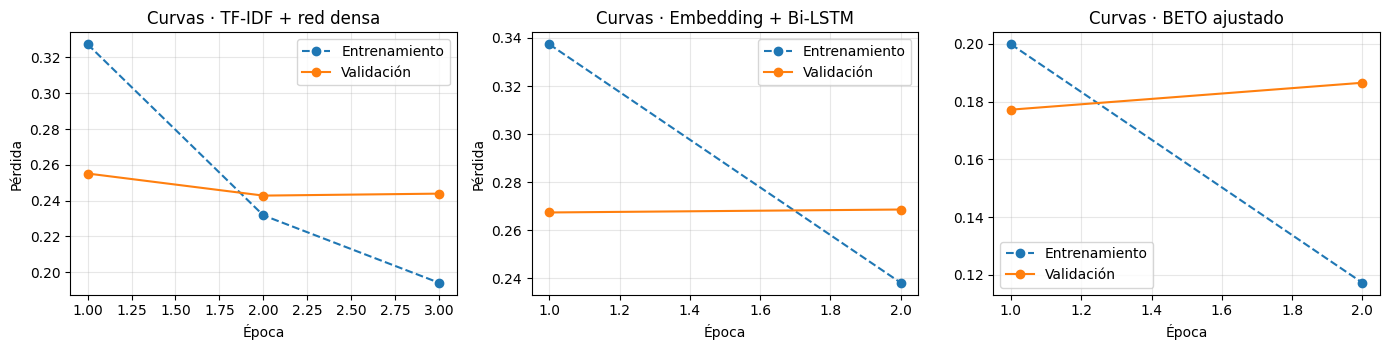

In [13]:
curvas_keras = [nombre for nombre, datos in candidatos.items() if "historia" in datos]
registro = pd.DataFrame(trainer.state.log_history)
beto_train = registro.dropna(subset=["loss"])
beto_val = registro.dropna(subset=["eval_loss"])

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, nombre in zip(ejes, curvas_keras):
    historia = candidatos[nombre]["historia"].history
    ax.plot(range(1, len(historia["loss"]) + 1), historia["loss"], "o--", label="Entrenamiento")
    ax.plot(range(1, len(historia["val_loss"]) + 1), historia["val_loss"], "o-", label="Validación")
    ax.set_title(f"Curvas · {nombre}")
    ax.set_xlabel("Época")
    ax.set_ylabel("Pérdida")
    ax.legend()
ejes[2].plot(beto_train["epoch"], beto_train["loss"], "o--", label="Entrenamiento")
ejes[2].plot(beto_val["epoch"], beto_val["eval_loss"], "o-", label="Validación")
ejes[2].set_title("Curvas · BETO ajustado")
ejes[2].set_xlabel("Época")
ejes[2].legend()
plt.tight_layout()
plt.show()

## 7. Elección con validación
**Regla, fijada antes de ver los resultados:**

1. Se usa siempre el umbral de 0.5.
2. Se elige el modelo **más simple** con un margen de al menos 1 punto sobre las dos especificaciones en validación. El orden es TF-IDF, Bi-LSTM, BETO. El punto de margen es porque 4,000 reseñas dejan un error de medición cercano a ±1.5 puntos.
3. Si ninguno llega a ese margen, se elige el de mayor margen y se reporta.

La simplicidad importa porque un modelo ligero es más barato de operar. Si el elegido es BETO, pesa más de 100 MB y hay que publicarlo en Hugging Face o Drive.

In [14]:
filas_val = []
for nombre, datos in candidatos.items():
    m = metricas(y_val, datos["probabilidad"](x_val))
    filas_val.append({"modelo": nombre, "tipo": datos["tipo"], "orden": datos["orden"], "peso_negativa": datos.get("peso"),
                      "parametros": datos["parametros"], "exhaustividad": m["exhaustividad"], "precision": m["precision"],
                      "exactitud": m["exactitud"], "margen": m["margen"]})
tabla_val = pd.DataFrame(filas_val)
tabla_val["cumple_val"] = (tabla_val["exhaustividad"] >= MIN_EXHAUSTIVIDAD) & (tabla_val["precision"] >= MIN_PRECISION)
display(tabla_val.drop(columns="orden").round(4))

solo_modelos = tabla_val[tabla_val["modelo"] != NOMBRE_BASE]
con_margen = solo_modelos[solo_modelos["margen"] >= MARGEN_MINIMO]
if len(con_margen):
    nombre_elegido = con_margen.sort_values("orden").iloc[0]["modelo"]
else:
    nombre_elegido = solo_modelos.sort_values("margen", ascending=False).iloc[0]["modelo"]
fila = tabla_val.set_index("modelo").loc[nombre_elegido]

aviso = "es el más simple con al menos 1 punto de margen" if len(con_margen) else "**ninguno** llegó a 1 punto de margen; es el de mayor margen"
display(Markdown(f"**Modelo elegido: {nombre_elegido}.** En validación tiene {fila['exhaustividad']:.1%} de exhaustividad, "
                 f"{fila['precision']:.1%} de precisión y {fila['exactitud']:.1%} de exactitud; {aviso}. Esta elección ya no cambia."))

,modelo,tipo,peso_negativa,parametros,exhaustividad,precision,exactitud,margen,cumple_val
0,Línea base (todo negativa),linea base,NaN,0,1.0000,0.5000,0.5000,-0.3500,False
1,TF-IDF + red densa,conjunto,1.6,960065,0.8750,0.9172,0.8980,-0.0250,False
2,Embedding + Bi-LSTM,recurrente,1.6,1304897,0.8925,0.8828,0.8870,-0.0075,False
3,BETO ajustado,transformer,1.6,109852418,0.9425,0.9186,0.9295,0.0425,True


**Modelo elegido: BETO ajustado.** En validación tiene 94.2% de exhaustividad, 91.9% de precisión y 93.0% de exactitud; es el más simple con al menos 1 punto de margen. Esta elección ya no cambia.

### Guardado, antes de abrir la prueba
Se guarda ahora porque, si el guardado fallara, se puede corregir sin haber usado la prueba. Un modelo de Keras se guarda completo, con su vectorizador, para que reciba texto directamente. Si fue BETO, se guardan el modelo y el tokenizador.

In [15]:
os.makedirs("modelo", exist_ok=True)
ES_BETO = nombre_elegido == "BETO ajustado"


def carpeta_mb(ruta):
    total = sum(os.path.getsize(os.path.join(raiz, f)) for raiz, _, archivos in os.walk(ruta) for f in archivos)
    return total / 1024**2


if ES_BETO:
    RUTA_MODELO = os.path.join("modelo", "modelo_resenas_beto")
    modelo_beto.save_pretrained(RUTA_MODELO)
    tokenizador.save_pretrained(RUTA_MODELO)
    print(f"Guardado en {RUTA_MODELO}: {carpeta_mb(RUTA_MODELO):.0f} MB. Pasa de 100 MB: hay que publicarlo y poner el enlace en el README.")
else:
    RUTA_MODELO = os.path.join("modelo", "modelo_resenas.keras")
    datos = candidatos[nombre_elegido]
    entrada = keras.Input(shape=(1,), dtype="string", name="texto")
    modelo_texto = keras.Model(entrada, datos["red"](datos["vectorizador"](entrada)), name="modelo_resenas")
    modelo_texto.save(RUTA_MODELO)

    recargado = keras.models.load_model(RUTA_MODELO)
    muestra = ds_textos(x_val[:64]).map(lambda t: tf.expand_dims(t, -1))
    prob_recargado = recargado.predict(muestra, verbose=0).ravel()
    iguales = np.allclose(prob_recargado, datos["probabilidad"](x_val[:64]), atol=1e-4)
    print(f"Guardado en {RUTA_MODELO}: {os.path.getsize(RUTA_MODELO) / 1024**2:.1f} MB")
    print(f"La recarga da las mismas probabilidades: {iguales}")
    assert iguales, "El modelo recargado no coincide. No abras la prueba: revisa el guardado."

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Guardado en modelo/modelo_resenas_beto: 420 MB. Pasa de 100 MB: hay que publicarlo y poner el enlace en el README.


## 8. Prueba del cliente, una sola vez
Se miden todos los modelos para llenar `resultados`, pero la elección de arriba no cambia. El candado de la primera línea evita repetir la medición sin darse cuenta.

`cumple` exige las dos métricas. Los tres modelos son propios, entrenados por el equipo.

In [16]:
assert "resultados" not in globals(), "La prueba ya se usó en esta sesión: su resultado no se debe volver a buscar."

metricas_prueba = {}
probs_prueba = {}
filas = []
for nombre, datos in candidatos.items():
    probs_prueba[nombre] = datos["probabilidad"](X_prueba)
    m = metricas(y_prueba, probs_prueba[nombre])
    metricas_prueba[nombre] = m
    cumple = bool(m["exhaustividad"] >= MIN_EXHAUSTIVIDAD and m["precision"] >= MIN_PRECISION)
    filas.append({"modelo": nombre, "tipo": datos["tipo"], "parametros": datos["parametros"], "exhaustividad": m["exhaustividad"],
                  "precision": m["precision"], "exactitud": m["exactitud"], "cumple": cumple, "elegido": nombre == nombre_elegido})

resultados = pd.DataFrame(filas)
resultados.to_csv("resultados_resenas.csv", index=False)
resultados

,modelo,tipo,parametros,exhaustividad,precision,exactitud,cumple,elegido
0,Línea base (todo negativa),linea base,0,1.000,0.500000,0.50000,False,False
1,TF-IDF + red densa,conjunto,960065,0.884,0.928084,0.90775,False,False
2,Embedding + Bi-LSTM,recurrente,1304897,0.884,0.892929,0.88900,False,False
3,BETO ajustado,transformer,109852418,0.953,0.925243,0.93800,True,True


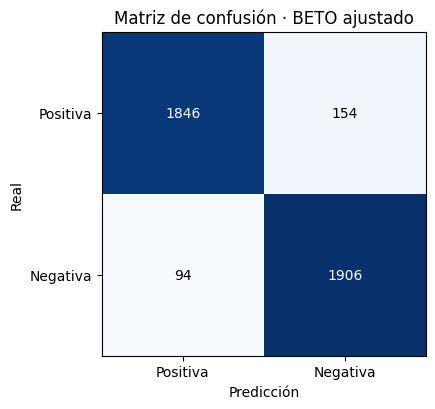


**En palabras del cliente, con BETO ajustado:**

- De cada 100 reseñas negativas, marca 95.3. Dejó pasar 94 de 2000. Intervalo al 95 %: 94.3% a 96.1%.
- De cada 100 reseñas que marca, 92.5 son negativas. Marcó 2060 y 154 eran positivas. Intervalo al 95 %: 91.3% a 93.6%.
- Exactitud: 93.8%.
- Reseñas de prueba idénticas a alguna de desarrollo: 54.

**Sí cumple** todas las especificaciones.


In [17]:
m = metricas_prueba[nombre_elegido]
negativas, marcadas = m["vp"] + m["fn"], m["vp"] + m["fp"]
ic_exh = intervalo_wilson(m["vp"], negativas)
ic_prec = intervalo_wilson(m["vp"], marcadas)
cumple_elegido = bool(resultados.loc[resultados["elegido"], "cumple"].iloc[0])

textos_desarrollo = set(des_train["text"]) | set(des_val["text"])
repetidas_prueba = sum(str(t) in textos_desarrollo for t in X_prueba)

matriz = np.array([[m["vn"], m["fp"]], [m["fn"], m["vp"]]])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(matriz, cmap="Blues")
ax.set_xticks([0, 1], ["Positiva", "Negativa"])
ax.set_yticks([0, 1], ["Positiva", "Negativa"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, matriz[i, j], ha="center", va="center", color="white" if matriz[i, j] > matriz.max() / 2 else "black")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión · {nombre_elegido}")
ax.grid(False)
plt.tight_layout()
plt.show()

veredicto = "**Sí cumple** todas las especificaciones." if cumple_elegido else ("**No cumple** todas las especificaciones. No se reajusta: "
            "se reconoce en el folleto y se explica qué haría falta para lograrlo.")
display(Markdown(f'''
**En palabras del cliente, con {nombre_elegido}:**

- De cada 100 reseñas negativas, marca {m['exhaustividad'] * 100:.1f}. Dejó pasar {m['fn']} de {negativas}. Intervalo al 95 %: {ic_exh[0]:.1%} a {ic_exh[1]:.1%}.
- De cada 100 reseñas que marca, {m['precision'] * 100:.1f} son negativas. Marcó {marcadas} y {m['fp']} eran positivas. Intervalo al 95 %: {ic_prec[0]:.1%} a {ic_prec[1]:.1%}.
- Exactitud: {m['exactitud']:.1%}.
- Reseñas de prueba idénticas a alguna de desarrollo: {repetidas_prueba}.

{veredicto}
'''))

### Justificación de la elección
**Elegimos BETO ajustado.** La regla se fijó antes de ver los resultados, y la elección se hizo solo con validación:

| Modelo | Peso | Exhaustividad | Precisión | Exactitud | Margen | Parámetros |
|---|---|---|---|---|---|---|
| TF-IDF + red densa | 1.6 | 87.5 % | 91.7 % | 89.8 % | −2.5 puntos | 960,065 |
| Embedding + Bi-LSTM | 1.6 | 89.2 % | 88.3 % | 88.7 % | −0.8 puntos | 1,304,897 |
| **BETO ajustado** | 1.6 | **94.2 %** | **91.9 %** | **93.0 %** | **+4.2 puntos** | 109,852,418 |

- **Es el único que cumple.** La regla pedía el modelo más simple con al menos 1 punto de margen. TF-IDF y Bi-LSTM quedaron debajo del 90 % de exhaustividad en validación, así que BETO no se eligió por ser el más complejo, sino porque los dos más simples no alcanzaron.
- **Su ventaja es real, no de medición.** Tiene 4.2 puntos de margen, cuando el error de medición con 4,000 reseñas ronda ±1.5 puntos. Supera a la Bi-LSTM por 5 puntos de exhaustividad y 3.6 de precisión.
- **Entiende mejor el contexto.** Es lo que se esperaría en reseñas con «pero» y negaciones, aunque no lo medimos aparte. Además se entrenó con solo 40,000 reseñas, una cuarta parte de las que usaron los otros.
- **Se conservó su mejor época.** Su pérdida de validación subió de 0.177 a 0.187 en la segunda época, y el entrenamiento guarda la de menor pérdida, que es la primera.

**Con honestidad:**

- **Costo:** tiene 84 veces más parámetros que la Bi-LSTM y pesa 420 MB. Hay que alojarlo en un servidor y publicarlo fuera del repositorio.
- **Peso de clase:** las dos redes de Keras eligieron el peso más alto que probamos, 1.6. Con pesos mayores tal vez habrían llegado a 90 %, pero eso no se probó. BETO heredó ese mismo peso, sin búsqueda propia.

La prueba no participó en esta decisión. Ahí BETO cumple con 95.3 % de exhaustividad y 92.5 % de precisión, y TF-IDF y Bi-LSTM no cumplen, con 88.4 % de exhaustividad cada uno.

## 9. Análisis de 3 errores
Tomo los errores más seguros del modelo elegido: dos negativas que no marcó, que son clientes molestos sin atender, y una positiva que marcó. Si no hay suficientes de un tipo, completo con el otro.

También se desglosan los aciertos por estrellas, porque 2★ y 4★ suelen ser más ambiguas que 1★ y 5★.

In [18]:
prob_elegido = probs_prueba[nombre_elegido]
pred_elegido = (prob_elegido >= UMBRAL).astype(int)
estrellas_prueba = prueba["estrellas"].to_numpy()

falsos_neg = np.where((y_prueba == 1) & (pred_elegido == 0))[0]
falsos_pos = np.where((y_prueba == 0) & (pred_elegido == 1))[0]
falsos_neg = falsos_neg[np.argsort(prob_elegido[falsos_neg])]
falsos_pos = falsos_pos[np.argsort(-prob_elegido[falsos_pos])]

errores = list(falsos_neg[:2]) + list(falsos_pos[:1])
sobrantes = list(falsos_neg[2:]) + list(falsos_pos[1:])
errores += sobrantes[:3 - len(errores)]

for numero, i in enumerate(errores, start=1):
    tipo_error = "negativa no marcada" if y_prueba[i] == 1 else "positiva marcada"
    print(f"Error {numero} · índice {i} · {estrellas_prueba[i]}★ · {tipo_error} · prob. negativa {prob_elegido[i]:.3f}")
    print(textwrap.fill(str(X_prueba[i]), width=110))
    print()

por_estrellas = pd.DataFrame({"estrellas": estrellas_prueba, "marcada": pred_elegido}).groupby("estrellas")["marcada"].agg(["size", "sum", "mean"])
por_estrellas.columns = ["reseñas", "marcadas como negativas", "proporción marcada"]
por_estrellas.round(3)

Error 1 · índice 1862 · 2★ · negativa no marcada · prob. negativa 0.003
Lo que se anuncia . Sin nada raro. A mis gatas les encanta y yo feliz para evitar que salga la arena.

Error 2 · índice 1638 · 2★ · negativa no marcada · prob. negativa 0.005
La aplicacion es muy completa por su variedad, uso y contenidos. Lo unico que le falla... es que el audio es
solo en ingles!

Error 3 · índice 2227 · 4★ · positiva marcada · prob. negativa 0.997
El producto de 10. El envío pésimo, ya que dejar un paquete en un buzón de exterior de una casa cuando está
lloviendo a mares. Os podéis imaginar el resultado. Nefasto por parte de la empresa de transporte



,reseñas,marcadas como negativas,proporción marcada
estrellas,,,
1,1000,988,0.988
2,1000,918,0.918
4,1000,105,0.105
5,1000,49,0.049


Los tres errores salen de los 248 que cometió el modelo en 4,000 reseñas de prueba: 94 negativas sin marcar y 154 positivas marcadas. Son los errores en los que estaba más seguro, así que no representan el error típico.

1. **Error 1, reseña 1862 (2★): negativa no marcada, con probabilidad de 0.003.** Dice: «A mis gatas les encanta y yo feliz». Todo el texto es positivo, sin ninguna queja. El modelo leyó bien; lo que no coincide son las 2 estrellas con lo que escribió la persona. **Consecuencia:** casi ninguna en la práctica, porque no hay una queja que atender, pero muestra que parte del error viene de la etiqueta.

2. **Error 2, reseña 1638 (2★): negativa no marcada, con probabilidad de 0.005.** Elogia la aplicación («muy completa») y al final da su única queja: «el audio es solo en ingles». La molestia no usa ninguna palabra negativa fuerte y queda en minoría frente a los elogios. **Consecuencia:** es el error que importa, porque un cliente con un problema concreto no pasa al frente de la fila.

3. **Error 3, reseña 2227 (4★): positiva marcada, con probabilidad de 0.997.** Dice «el producto de 10», pero luego llama al envío «pésimo» y «nefasto». Las 4 estrellas califican el producto, y el texto se queja del transporte. **Consecuencia:** cuenta como falsa alarma, pero atención a clientes sí tendría algo que responder aquí.

**Lo que enseñan juntos:** las estrellas no siempre coinciden con la queja, que es lo que le interesa al cliente. El modelo acierta casi siempre en los extremos y duda más en las zonas mixtas: marca 98.8 % de las reseñas de 1★ y 91.8 % de las de 2★, y por error marca 10.5 % de las de 4★ y 4.9 % de las de 5★. La probabilidad tampoco avisa de estos casos: en los tres errores fue casi 0 o casi 1.

## 10. Limitaciones, con números
Estas pruebas van **aparte de la prueba del cliente**, y alimentan el folleto.

### Español de México
Los datos son de Amazon España y el cliente es mexicano. Probamos 16 frases redactadas con apoyo de IA y revisadas por el equipo, con modismos mexicanos y sarcasmo.

In [19]:
frases = [
    ("Está bien gacho el producto, ni lo compren", 1, "modismo"),
    ("Me salió bien chafa, a los dos días ya no jaló", 1, "modismo"),
    ("Qué mala onda, el paquete nunca llegó y nadie me contesta", 1, "modismo"),
    ("Puro cuento, me vieron la cara con este producto", 1, "modismo"),
    ("Llegó todo madreado y ni quien responda", 1, "modismo"),
    ("Está de la patada, pedí azul y me mandaron rojo", 1, "modismo"),
    ("Está bien chido, me encantó", 0, "modismo"),
    ("Está padrísimo y salió barato", 0, "modismo"),
    ("Muy buena onda el vendedor, todo llegó perfecto", 0, "modismo"),
    ("Está de poca madre, lo recomiendo", 0, "modismo"),
    ("Jala al cien y llegó rapidísimo", 0, "modismo"),
    ("Quedó bien chilo, ya pedí otro", 0, "modismo"),
    ("Excelente servicio, solo tardaron dos meses en entregarlo", 1, "sarcasmo"),
    ("Qué maravilla, se rompió el primer día", 1, "sarcasmo"),
    ("Muchas gracias por mandarme una caja vacía", 1, "sarcasmo"),
    ("Súper calidad, duró exactamente una semana", 1, "sarcasmo"),
]
tabla_frases = pd.DataFrame(frases, columns=["frase", "negativa_esperada", "grupo"])
tabla_frases["prob_negativa"] = candidatos[nombre_elegido]["probabilidad"](tabla_frases["frase"].to_numpy(dtype=object))
tabla_frases["acierto"] = (tabla_frases["prob_negativa"] >= UMBRAL).astype(int) == tabla_frases["negativa_esperada"]
display(tabla_frases.round(3))
display(tabla_frases.groupby("grupo")["acierto"].agg(aciertos="sum", frases="size"))

,frase,negativa_esperada,grupo,prob_negativa,acierto
0,"Está bien gacho el producto, ni lo compren",1,modismo,0.851,True
1,"Me salió bien chafa, a los dos días ya no jaló",1,modismo,0.899,True
2,"Qué mala onda, el paquete nunca llegó y nadie me contesta",1,modismo,0.998,True
3,"Puro cuento, me vieron la cara con este producto",1,modismo,0.944,True
4,Llegó todo madreado y ni quien responda,1,modismo,0.981,True
5,"Está de la patada, pedí azul y me mandaron rojo",1,modismo,0.983,True
6,"Está bien chido, me encantó",0,modismo,0.006,True
7,Está padrísimo y salió barato,0,modismo,0.889,False
8,"Muy buena onda el vendedor, todo llegó perfecto",0,modismo,0.003,True
9,"Está de poca madre, lo recomiendo",0,modismo,0.051,True


,aciertos,frases
grupo,,
modismo,11,12
sarcasmo,0,4


### Reseñas de 3 estrellas
La prueba no las incluye, pero la tienda sí las recibirá. Medimos qué pasa con las de la partición de validación, que ningún modelo usó para entrenar.

De 1,000 reseñas de 3★, el modelo marca 59.3% como negativas.


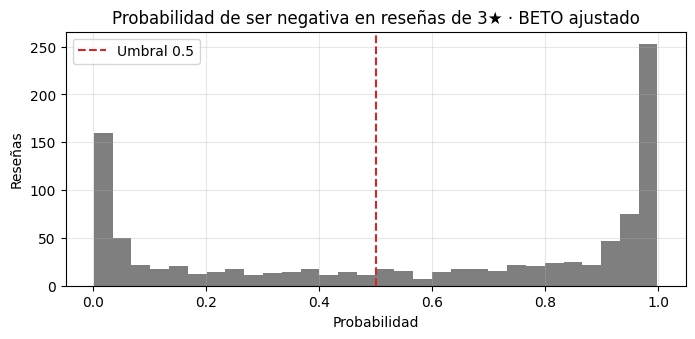

In [20]:
tres_estrellas = val[val["estrellas"] == 3]["text"].astype(str).to_numpy(dtype=object)
prob_tres = candidatos[nombre_elegido]["probabilidad"](tres_estrellas)
marcadas_tres = float((prob_tres >= UMBRAL).mean())
print(f"De {len(tres_estrellas):,} reseñas de 3★, el modelo marca {marcadas_tres:.1%} como negativas.")

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.hist(prob_tres, bins=30, color="tab:gray")
ax.axvline(UMBRAL, color="tab:red", linestyle="--", label="Umbral 0.5")
ax.set_title(f"Probabilidad de ser negativa en reseñas de 3★ · {nombre_elegido}")
ax.set_xlabel("Probabilidad")
ax.set_ylabel("Reseñas")
ax.legend()
plt.show()

### Proporción real de reseñas negativas
La prueba tiene 50 % de negativas, porque así está construida. La tienda puede tener menos, y entonces la precisión baja aunque el modelo sea el mismo. La tabla usa las tasas de la prueba en un día hipotético de 10,000 reseñas. No incluye las de 3★, y las proporciones son escenarios, no mediciones.

In [21]:
m = metricas_prueba[nombre_elegido]
tasa_falsa_alarma = m["fp"] / (m["fp"] + m["vn"])
RESENAS_DIA = 10_000
filas_prevalencia = []
for proporcion in [0.05, 0.10, 0.20, 0.50]:
    negativas_dia = RESENAS_DIA * proporcion
    detectadas = negativas_dia * m["exhaustividad"]
    falsas_alarmas = (RESENAS_DIA - negativas_dia) * tasa_falsa_alarma
    filas_prevalencia.append({"% negativas": round(proporcion * 100), "negativas al día": round(negativas_dia), "detectadas": round(detectadas),
                              "sin marcar": round(negativas_dia - detectadas), "falsas alarmas": round(falsas_alarmas),
                              "reseñas marcadas": round(detectadas + falsas_alarmas),
                              "de cada 100 marcadas, son negativas": round(detectadas / (detectadas + falsas_alarmas) * 100, 1)})
tabla_prevalencia = pd.DataFrame(filas_prevalencia)
display(Markdown(f"**Día hipotético de {RESENAS_DIA:,} reseñas**, con {nombre_elegido}:"))
tabla_prevalencia

**Día hipotético de 10,000 reseñas**, con BETO ajustado:

,% negativas,negativas al día,detectadas,sin marcar,falsas alarmas,reseñas marcadas,"de cada 100 marcadas, son negativas"
0,5,500,476,24,732,1208,39.4
1,10,1000,953,47,693,1646,57.9
2,20,2000,1906,94,616,2522,75.6
3,50,5000,4765,235,385,5150,92.5


**Cifras para el folleto:**

- **México:** 11 de 12 frases con modismos clasificadas bien; falló en «Está padrísimo y salió barato», marcada con 0.889. Son pocas frases y no representan a sus clientes: detectan un riesgo, pero no miden el desempeño en México.
- **Sarcasmo:** 0 de 4. Ninguna frase sarcástica fue marcada, por lo que estas quejas pasarían como positivas.
- **3 estrellas:** marca 59.3 % de 1,000 reseñas de 3★. El histograma muestra que el modelo las manda con seguridad a un extremo u otro, en vez de dudar.
- **Proporción de negativas:** con 10 % de negativas, solo 57.9 de cada 100 marcadas lo serían. Con estas tasas, la precisión cae debajo de 85 % cuando las negativas son menos de 31 % del total. Es un cálculo hipotético, sin contar las de 3★, y se resuelve de `0.953 p / (0.953 p + 0.077 (1 − p)) = 0.85`.
- **Repetidas en la prueba:** 54 de 4,000 reseñas son idénticas a alguna de desarrollo. No cambian el veredicto: en el peor caso, sin ellas, quedarían 95.2 % de exhaustividad y 92.3 % de precisión.

**Aviso ético:** el modelo sirve para ordenar la atención, no para decidir sobre las personas. No debe borrar ni ocultar reseñas, ni responder solo. Una reseña sin marcar también merece atención, y conviene revisar que no atienda peor a quienes escriben con modismos, con faltas o en otras variantes del español.

**Propuesta de mejora:** etiquetar reseñas reales de Compra Fácil Bajío, ajustar el modelo con ellas y medir por categoría y por región.

## 11. Entrega
El modelo elegido ya se guardó en el paso 7. Aquí se empaquetan el CSV y el modelo para descargarlos. Si el elegido es BETO, el paquete lleva solo el CSV, y la carpeta del modelo se publica aparte.

El cuaderno se descarga aparte, **con sus salidas**: Archivo → Descargar → Descargar .ipynb. Guárdalo como `DEV_resenas.ipynb`.

In [22]:
os.makedirs("entrega_resenas", exist_ok=True)
shutil.copy("resultados_resenas.csv", "entrega_resenas/")
if not ES_BETO:
    shutil.copytree("modelo", "entrega_resenas/modelo", dirs_exist_ok=True)
else:
    print(f"BETO elegido: publica {RUTA_MODELO} en Hugging Face o Drive; no va en el paquete.")
tabla_frases.to_csv("entrega_resenas/frases_mexico.csv", index=False)
paquete = shutil.make_archive("entrega_resenas", "zip", "entrega_resenas")
print(f"Paquete listo: {paquete}")

try:
    from google.colab import files
    files.download(paquete)
except ImportError:
    print("Fuera de Colab: toma el .zip de la carpeta actual.")

BETO elegido: publica modelo/modelo_resenas_beto en Hugging Face o Drive; no va en el paquete.
Paquete listo: /content/entrega_resenas.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>